# 02 — Prepare the data

Split the data, fill missing answers, scale numbers and encode categories.

Open from the notebooks folder. Saved outputs are from the earlier execution; the simplified source has not been rerun in full.

## Imports and columns

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_columns = [
    'Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
    'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
    'Family_Support', 'Attendance_Rate',
]
categorical_columns = [
    'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
    'Previous_Mental_Health_History',
]

## Train/test split

Use seed 42 and stratification to keep class proportions similar.

In [2]:
df = pd.read_csv('../data/raw/student_mental_health.csv')
X = df[numeric_columns + categorical_columns]
y = df['Mental_Health_Risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(1600, 15)
(400, 15)


## Missing answers and unusual values

Keep plausible extremes. Learn missing-value replacements from training data only.

In [3]:
display(X_train.isna().sum())
display(X_train[numeric_columns].describe())

Age                                0
Year_of_Study                      0
Sleep_Hours                       54
Study_Hours_Per_Week               0
GPA                               36
Social_Media_Hours                48
Screen_Time_Hours                  0
Financial_Stress                  76
Family_Support                    36
Attendance_Rate                   39
Gender                             0
Physical_Activity                  0
Part_Time_Job                      0
Diet_Quality                      55
Previous_Mental_Health_History     0
dtype: int64

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,1600.000000,1600.000000,1546.000000,1600.000000,1564.000000,1552.000000,1600.000000,1524.000000,1564.000000,1561.000000
mean,21.135625,2.620000,6.751294,19.976062,2.564668,6.035116,8.577125,5.963648,6.524041,85.046637
std,2.129569,1.314983,1.122965,5.768956,0.346789,1.134181,1.659197,1.909517,1.843943,7.280687
min,17.000000,1.000000,3.600000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.300000,7.400000,4.500000,5.200000,80.200000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.500000,24.000000,2.800000,6.800000,9.700000,7.400000,8.000000,90.100000
max,28.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


## Preprocessing

Use median imputation and scaling for numbers, and mode imputation and one-hot encoding for categories.

In [4]:
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns),
])

## Transform the training data

This preview learns from training rows. Model training will fit its own preprocessing inside cross-validation.

In [5]:
train_prepared = preprocessor.fit_transform(X_train)
encoded = pd.DataFrame(train_prepared, columns=preprocessor.get_feature_names_out())
display(encoded.head())
print(encoded.shape)

,numeric__Age,numeric__Year_of_Study,numeric__Sleep_Hours,numeric__Study_Hours_Per_Week,numeric__GPA,numeric__Social_Media_Hours,numeric__Screen_Time_Hours,numeric__Financial_Stress,numeric__Family_Support,numeric__Attendance_Rate,...,categorical__Physical_Activity_High,categorical__Physical_Activity_Low,categorical__Physical_Activity_Moderate,categorical__Part_Time_Job_No,categorical__Part_Time_Job_Yes,categorical__Diet_Quality_Average,categorical__Diet_Quality_Good,categorical__Diet_Quality_Poor,categorical__Previous_Mental_Health_History_No,categorical__Previous_Mental_Health_History_Yes
0,-0.063706,-0.471636,-1.404182,-0.238603,0.074214,0.148597,1.098992,0.713748,0.643008,-1.244652,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.875744,-1.232340,-1.676036,-1.330997,-0.976093,0.327697,0.194658,-0.842691,0.368687,-0.465696,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-1.003157,-0.471636,0.408177,-0.516037,-1.034443,-0.299153,-0.830254,-0.305988,0.752736,0.772288,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.875744,-1.232340,1.404975,-0.082547,0.891120,0.775447,1.098992,0.821088,-0.948052,-0.215317,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.406019,0.289067,0.408177,0.663055,-0.275888,-0.388703,-0.347943,0.660077,0.697872,-1.453301,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0


(1600, 23)


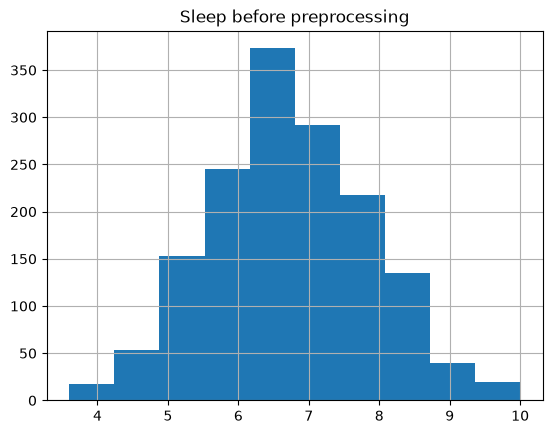

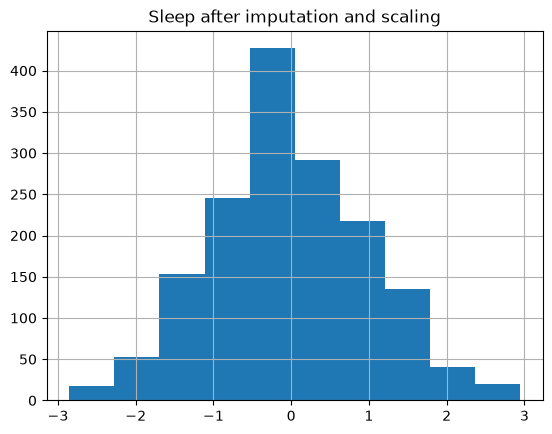

In [6]:
X_train['Sleep_Hours'].hist()
plt.title('Sleep before preprocessing')
plt.show()
encoded['numeric__Sleep_Hours'].hist()
plt.title('Sleep after imputation and scaling')
plt.show()

## Transform the test data

Use transform, without fitting again, so the test rows do not affect the learned values.

In [7]:
test_prepared = preprocessor.transform(X_test)
display(pd.DataFrame(test_prepared).head())
print(test_prepared.shape)

,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
0,1.345470,1.810475,-1.404182,1.408656,2.174828,-0.299153,-0.528810,0.230715,-0.289683,-1.230742,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-0.063706,0.289067,0.226941,0.402961,0.190915,-3.254301,-2.036034,0.499067,0.368687,-0.326597,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.406019,1.049771,-0.769856,0.298923,-0.976093,0.059047,0.254947,-1.540404,1.575698,0.201981,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,1.815195,-1.232340,0.136323,-0.047868,-0.625990,0.327697,0.134369,0.445396,0.368687,-1.355932,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
4,-0.063706,0.289067,-1.494800,0.229565,0.103390,-0.388703,0.074080,-1.916096,-2.539112,0.688829,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


(400, 23)


## Check class balance

The three classes are nearly balanced. No resampling is needed.

In [8]:
display(y_train.value_counts())

Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64